In [1]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) -- 
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'GPU: Tesla T4'

In [2]:
# 1. Silence C++ backend warnings (Must be before importing/using TF operations)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

try:
    import tensorflow as tf
except:
    !uv pip install tensorflow
    import tensorflow as tf

import logging

# 2. Silence Python level TensorFlow/ABSL warnings
tf.get_logger().setLevel(logging.ERROR)
logging.getLogger('tensorflow').setLevel(logging.ERROR)
logging.getLogger('absl').setLevel(logging.ERROR)

In [3]:
## -- keras library --
try:
    from scikeras.wrappers import KerasClassifier
except:
    !uv pip install -q scikeras
    from scikeras.wrappers import KerasClassifier

print()
# !pip show scikeras

In [4]:
!uv pip install -q ipywidgets
!uv pip install -q pygraphviz

!apt-get install -qq -y graphviz graphviz-dev && pip install -qq pydot

Selecting previously unselected package at-spi2-common.
(Reading database ... 129796 files and directories currently installed.)
Preparing to unpack .../00-at-spi2-common_2.52.0-1build1_all.deb ...
Unpacking at-spi2-common (2.52.0-1build1) ...
Selecting previously unselected package libatk1.0-0t64:amd64.
Preparing to unpack .../01-libatk1.0-0t64_2.52.0-1build1_amd64.deb ...
Unpacking libatk1.0-0t64:amd64 (2.52.0-1build1) ...
Selecting previously unselected package libgtk2.0-common.
Preparing to unpack .../02-libgtk2.0-common_2.24.33-4ubuntu1.1_all.deb ...
Unpacking libgtk2.0-common (2.24.33-4ubuntu1.1) ...
Selecting previously unselected package libxcomposite1:amd64.
Preparing to unpack .../03-libxcomposite1_1%3a0.4.5-1build3_amd64.deb ...
Unpacking libxcomposite1:amd64 (1:0.4.5-1build3) ...
Selecting previously unselected package libgtk2.0-0t64:amd64.
Preparing to unpack .../04-libgtk2.0-0t64_2.24.33-4ubuntu1.1_amd64.deb ...
Unpacking libgtk2.0-0t64:amd64 (2.24.33-4ubuntu1.1) ...
Sele

In [5]:
# %load_ext cuml.accel
# %load_ext cudf.pandas

In [6]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [7]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import shutil
import itertools
from tqdm.auto import tqdm
from time import time, sleep

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import roc_auc_score, PredictionErrorDisplay
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split

from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, TargetEncoder as skTE

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer

import warnings
# tf.get_logger().setLevel('ERROR')
warnings.simplefilter('ignore')

## -- Set Configuration --
# sklearn.set_config(transform_output="pandas")
# pd.options.mode.copy_on_write = True
pd.set_option("display.max_columns", 100)
sns.set_style("whitegrid")
# plt.style.use('ggplot')

def seed_everything(seed: int):
    print(f"✓ Seed everything at {seed}")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(42)

✓ Seed everything at 42


In [8]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 12,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})

sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [9]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH = "/kaggle/input/competitions/playground-series-s6e10/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train = pd.read_csv(PATH+"train.csv")
    test = pd.read_csv(PATH+"test.csv")

    ORIG_PATH = "/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/"
    orig = pd.read_csv(ORIG_PATH+"data.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")

    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e10 | Airline Satisfaction/_airline_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig = pd.read_csv(PATH+"data.csv")

## =================================================================================

TARGET, ID = 'satisfaction', 'id'

train[TARGET] = train[TARGET].map({True: 1, False: 0})
orig[TARGET] = orig[TARGET].map({True: 1, False: 0})

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()

cat_cols  = [c for c in obj if c not in [TARGET, ID]]
num_cols  = [c for c in train.columns if c not in cat_cols+[TARGET, ID]]
base_cols = [c for c in train.columns if c not in [TARGET, ID]]

train = train[base_cols+[TARGET]]
orig  = orig[base_cols+[TARGET]]
test  = test[base_cols]

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")
print(f"Total Numerical: {len(num_cols)}")
print(f"Total Categorical: {len(cat_cols)}")
print(f"Total base features: {len(base_cols)}")

Train shape: (699635, 22)
Test shape: (299844, 21)
Orig shape: (129880, 22)

Frame type: <class 'pandas.core.frame.DataFrame'>
Total Numerical: 17
Total Categorical: 4
Total base features: 21


In [10]:
for c in num_cols:
    train[c] = train[c].fillna(0.0)
    test[c]  = test[c].fillna(0.0)
    orig[c]  = orig[c].fillna(0.0)

print(train.isna().sum())

Age                                  0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
Gender                               0
Customer Type                        0
Type of Travel                       0
Class                                0
satisfaction                         0
dtype: int64


In [11]:
train_len = len(train)
test_len  = len(test)

n_unique = train.nunique().sort_values()
n_unique

satisfaction                            2
Type of Travel                          2
Customer Type                           2
Gender                                  2
Class                                   3
Baggage handling                        5
Gate location                           6
Departure/Arrival time convenient       6
Leg room service                        6
Checkin service                         6
On-board service                        6
Inflight wifi service                   6
Food and drink                          6
Online boarding                         6
Seat comfort                            6
Ease of Online booking                  6
Inflight entertainment                  6
Cleanliness                             6
Age                                    75
Departure Delay in Minutes            167
Arrival Delay in Minutes              168
Flight Distance                      3474
dtype: int64

In [12]:
def get_weights(y, y_true, opt='auto'):
    """
    y: Current y labels -> numpy array or series
    y_true: True labels -> numpy array or series
    opt: 'auto' generate weight or pass a custom dict -> label: weight
    """
    if opt != 'auto':
        class_weights = opt
        sample_weights = np.array([class_weights[label] for label in y])
        return class_weights
    else:
        classes_ = np.unique(y_true)
        weights_ = compute_class_weight('balanced', classes=classes_, y=y_true)
        class_weights = dict(zip(classes_, weights_))
        sample_weights = np.array([class_weights[label] for label in y])
        return class_weights

print("- Helper Functions Ready -")

- Helper Functions Ready -


In [13]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class TargetEncoder(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}
        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)
        return X

In [14]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df, on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


## FEATURE ENGINEERING

In [15]:
# ## -- Cyclic encoding --
# cyclic_cols = []
# cy_cols = ["Daily_Commute_km"]

# for col in tqdm(cy_cols):
#     for p in [12]:
#         n_s = f"{col}_sin_{p}"

#         train[n_s] = np.sin(2 * np.pi * train[col] / p).astype('float32')
#         test[n_s]  = np.sin(2 * np.pi * test[col] / p).astype('float32')
#         orig[n_s]  = np.sin(2 * np.pi * orig[col] / p).astype('float32')
#         cyclic_cols.append(n_s)

#         # n_c = f"{col}_cos_{p}"
#         # train[n_c] = np.cos(2 * np.pi * train[col] / p).astype('float32')
#         # test[n_c] = np.cos(2 * np.pi * test[col] / p).astype('float32')
#         # orig[n_c] = np.cos(2 * np.pi * orig[col] / p).astype('float32')
#         # cyclic_cols.append(n_c)

# # num_cols.extend(cyclic_cols)

# print(f"Cylcic Features created: {len(cyclic_cols)}")
# display(train[cyclic_cols].describe().T)

# train[cyclic_cols]

In [16]:
## -- DIGITS EXTRACTION --

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]

combined = pd.concat([train, test, orig])

digit_cols = []
cols_select = ["Flight Distance"] #, "Age", "Arrival Delay in Minutes", "Departure Delay in Minutes"]

for col in cols_select:
    scaled = (combined[col].fillna(0) * (10**4)).astype('int64')
    for k in range(-4, 4):
        dig_col = f"{col}_dig_{k}"
        combined[dig_col] = (scaled // 10**(k+4) % 10).astype('int32').astype('category')
        # combined[dig_col] = (combined[col].fillna(0) // (10**k) % 10).astype('int32').astype('category')
        digit_cols.append(dig_col)

train = combined.iloc[:train_len]
test = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig = combined.iloc[-len(orig):]

# Check nunique, and find which ones are < 2
unique_counts = train[digit_cols].nunique()
drop_cols = unique_counts[unique_counts < 2].index.tolist()

# update digit cols for keep
digit_cols = [i for i in set(digit_cols) if i not in set(drop_cols)]

# drop constant features
train = train.drop(columns=drop_cols)
test  = test.drop(columns=drop_cols)
orig  = orig.drop(columns=drop_cols)

del combined
print(f"Total digit features: {len(digit_cols)}\n")

train[digit_cols].nunique()

Total digit features: 4



Flight Distance_dig_2    10
Flight Distance_dig_3     5
Flight Distance_dig_0    10
Flight Distance_dig_1    10
dtype: int64

In [17]:
## -- NUMERIC TO CATEGORY for TargetEncoding -- ⚠️

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Features before operation:", len(FEATURES))

combined = pd.concat([train, test, orig])
## ------------------------------------------------------------------------

# # -- Duplicate Nums as Cats -- ⚠️ used_all numericals
nums_to_cats = []
select_nc = ["Flight Distance", "Age"] #, "Age", "Arrival Delay in Minutes", "Departure Delay in Minutes"]
for c in tqdm(select_nc, desc="nums_to_cats"):
    new_cat = f"{c}_cat_"
    combined[new_cat] = (pd.factorize(combined[c])[0]).astype('int32')
    # combined[n] = combined[n].astype('category')
    nums_to_cats.append(new_cat)
FEATURES = list(set(FEATURES + nums_to_cats))

## ------------------------------------------------------------------------
train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

del combined
print("Features after operation:", len(FEATURES))

Features before operation: 25


nums_to_cats:   0%|          | 0/2 [00:00<?, ?it/s]

Features after operation: 27


In [18]:
# ## -- Frequency encoding -- ⚠️
# freq_cols = []

# combined = pd.concat([train, test], ignore_index=True)
# select_freq = ["Flight Distance"] #, "Age", "Arrival Delay in Minutes", "Departure Delay in Minutes"]

# print("\nCreating frequencies (Safe Global Mapping)...")
# for col in select_freq:
#     n = f"_freq_{col}"
#     print(f"⧗ {n}", end="")
    
#     # Calculate frequencies using ONLY train
#     freq_map = train[col].value_counts(dropna=False, normalize=False).to_dict()

#     # Map the training-derived frequencies across all datasets safely
#     train[n] = train[col].map(freq_map).fillna(0).astype("float32")
#     test[n] = test[col].map(freq_map).fillna(0).astype("float32")
#     orig[n] = orig[col].map(freq_map).fillna(0).astype("float32")

#     freq_cols.append(n)
#     print()

# # num_cols = list(set(num_cols + freq_cols))
# FEATURES = list(set(FEATURES + freq_cols))

# print(f"\n *** Total frequency features: {len(freq_cols)}")

In [19]:
## -- Factorize cat_cols -- ⚠️

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Total features before operation:", len(FEATURES))

combined = pd.concat([train, test, orig])
## ------------------------------------------------------------------------
for c in tqdm(cat_cols, desc="factorize_cats"):
    combined[c] = (pd.factorize(combined[c])[0]).astype('int32')
## ------------------------------------------------------------------------
# groupers = []
# for col in service_cols:
#     n_col = f"{col}_dist__GROUPBY".strip()
#     combined[n_col] = combined.groupby(['Flight Distance'])[col].transform('mean')
#     groupers.append(n_col)
# FEATURES = list(set(FEATURES + groupers))
## ------------------------------------------------------------------------
for c in tqdm(cat_cols, desc="categorize_cats"):
    combined[c] = combined[c].astype("category")

train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

del combined
print("Total features after operation:", len(FEATURES))

Total features before operation: 27


factorize_cats:   0%|          | 0/4 [00:00<?, ?it/s]

categorize_cats:   0%|          | 0/4 [00:00<?, ?it/s]

Total features after operation: 27


In [20]:
# ## FLOOR/BIN FEATURES -- ⚠️
# floor_cols = []

# combined = pd.concat([train, test, orig])

# # for f in tqdm([1000], desc='Floor features (bins)'):
# #     # print(f, end='-> ')
# #     for c in ['Flight Distance']:
# #         f_name = f"{c}_flr{f}"
# #         print(f" ⧗ {f_name}", end='... ')
# #         combined[f_name] = (combined[c].fillna(0) // f).astype('int32')
# #         # combined[f_name] = (combined[c].fillna(0) // f).astype('int32').astype('category')
# #         floor_cols.append(f_name)
# #         print()

# # for f in tqdm([10], desc='Floor features (bins)'):
# #     # print(f, end='-> ')
# #     for c in ['Departure Delay in Minutes', 'Arrival Delay in Minutes']:
# #         f_name = f"{c}_//_{f}"
# #         print(f" ⧗ {f_name}", end='... ')
# #         combined[f_name] = (combined[c] // f).astype('int32')
# #         floor_cols.append(f_name)
# #         print()

# for f in tqdm([10], desc='Floor features (bins)'):
#     # print(f, end='-> ')
#     for c in ['Age']:
#         age_n = f"{c}_flr{f}"
#         print(f" ⧗ {age_n}", end='... ')
#         combined[age_n] = (combined[c] // f).astype('int32')
#         floor_cols.append(age_n)
#         print()

# # combined[f"age{f}_X_dist1000"] = combined[age_n] * combined[f_name]

# # FEATURES = list(set(FEATURES + floor_cols))

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# del combined
# print(f"\n*** Total floor features: {len(floor_cols)}")

# print(train[floor_cols].nunique(dropna=False))

In [21]:
## -- INTERACTIONS -- ⚠️

INTER = []
combined = pd.concat([train, test, orig], ignore_index=True)

comb = [c for c in num_cols if (train[c].nunique() < 10) and (c in base_cols)]
# ------------------------------------------------------------------------
# combo_2_1 = list(itertools.combinations(['Class']+[age_n], 2))
# for c1, c2 in tqdm(combo_2_1, desc='Pairwise Sync Encoding'):
#     n_col = f"Bi_{c1}_X_{c2}".replace(" ", "")
#     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str)
#     combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
#     # combined[n_col] = combined[n_col].astype('category')
#     INTER.append(n_col)

combo_3_1 = list(itertools.combinations(cat_cols, 3)) # +[age_n]
for c1, c2, c3 in tqdm(combo_3_1, desc='Triplewise Sync Encoding'):
    n_col = f"Tri_{c1}_X_{c2}_X_{c3}".replace(" ", "")
    combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str) + '_' + combined[c3].astype(str)
    combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
    # combined[n_col] = combined[n_col].astype('category')
    INTER.append(n_col)

# combo_1_to_many = list(itertools.product(cat_cols, [age_n]))
# for c1, c2 in tqdm(combo_1_to_many, desc='One-2-Many Sync Encoding'):
#     n_col = f"Bi2_{c1}_X_{c2}".replace(" ", "")
#     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str)
#     combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
#     # combined[n_col] = combined[n_col].astype('category')
#     INTER.append(n_col)
# ------------------------------------------------------------------------

for n_col in INTER:
    train[n_col] = combined[n_col].iloc[:train_len].values
    test[n_col]  = combined[n_col].iloc[train_len:train_len + test_len].values
    orig[n_col]  = combined[n_col].iloc[train_len + test_len:].values

print(f"Total Interaction Features: {INTER}")

del combined
# train[INTER].head()

Triplewise Sync Encoding:   0%|          | 0/4 [00:00<?, ?it/s]

Total Interaction Features: ['Tri_Gender_X_CustomerType_X_TypeofTravel', 'Tri_Gender_X_CustomerType_X_Class', 'Tri_Gender_X_TypeofTravel_X_Class', 'Tri_CustomerType_X_TypeofTravel_X_Class']


In [22]:
print(f"Train shape {train.shape}")
train.head()

Train shape (699635, 32)


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction,Flight Distance_dig_0,Flight Distance_dig_1,Flight Distance_dig_2,Flight Distance_dig_3,Flight Distance_cat_,Age_cat_,Tri_Gender_X_CustomerType_X_TypeofTravel,Tri_Gender_X_CustomerType_X_Class,Tri_Gender_X_TypeofTravel_X_Class,Tri_CustomerType_X_TypeofTravel_X_Class
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,0,0,0,0,0.0,4,9,6,0,0,0,0,0,0,0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,1,0,1,1,1.0,1,5,6,0,1,1,1,1,1,1
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,0,0,0,0,0.0,1,7,3,1,2,2,0,0,0,0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,1,0,0,0,0.0,6,1,6,1,3,3,2,2,2,0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,0,1,1,0,0.0,1,8,4,0,4,4,3,3,3,2


# ML TRAINING

In [23]:
## -- SAMPLE MLP VIEWER --
n_features = len(FEATURES)
units = [128, 256, 128]

seq_layers = []
seq_layers.append(tf.keras.Input(shape=(n_features,)))
seq_layers.append(tf.keras.layers.BatchNormalization())

for i in range(len(units)):
    if i < (len(units) - 1):
        d = max(64, units[0] // (2**i))
    else:
        d = 64

    seq_layers.append(tf.keras.layers.Dense(units=d, activation='relu'))
    seq_layers.append(tf.keras.layers.BatchNormalization())
    seq_layers.append(tf.keras.layers.Dropout(0.1))

# Final output layer
seq_layers.append(tf.keras.layers.Dense(1, activation='sigmoid'))

# 3. Create the Sequential model for the "head"
model = tf.keras.Sequential(seq_layers)

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="binary_crossentropy",
    metrics=[tf.keras.metrics.AUC(name='auc')]
)

model.summary()

I0000 00:00:1792799706.389454      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792799706.393418      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ batch_normalization             │ (None, 27)             │           108 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,197 (67.18 KB)

 Trainable params: 16,631 (64.96 KB)

 Non-trainable params: 566 (2.21 KB)

In [24]:
def keras_mlp(meta, lr, units, act, drop):
    print(f"⚡️ Keras MLP Build")
    # SciKeras passes feature count after ColumnTransformer transformations in meta
    n_features = meta["n_features_in_"]
    seq_layers = []

    # 1. Add Input and the critical initial BatchNormalization layer
    seq_layers.append(tf.keras.Input(shape=(n_features,)))
    seq_layers.append(tf.keras.layers.BatchNormalization())

    # 2. Loop explicitly over your units list to match the architecture
    for u in units:
        seq_layers.append(tf.keras.layers.Dense(units=u, activation=act))
        seq_layers.append(tf.keras.layers.BatchNormalization())
        seq_layers.append(tf.keras.layers.Dropout(drop))

    # 3. Final output layer
    seq_layers.append(tf.keras.layers.Dense(1, activation='sigmoid'))

    # Compile model
    model = tf.keras.Sequential(seq_layers)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name='auc')]
    )
    return model

print("⚙️ Keras MLP model ⚙️")


⚙️ Keras MLP model ⚙️


In [25]:
def keras_seq(meta, lr, units, act, drop):
    print(f"⚡️ Keras SEQUENTIAL Build")
    # SciKeras passes feature count after ColumnTransformer transformations in meta
    n_features = meta["n_features_in_"]

    model = tf.keras.Sequential([
        tf.keras.Input(shape=(n_features,)),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dense(units[0], activation=act),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(drop),
        tf.keras.layers.Dense(units[1], activation=act),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(drop),
        tf.keras.layers.Dense(units[2], activation=act),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(drop),
        tf.keras.layers.Dense(1, activation='sigmoid'),
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name='auc')]
    )
    return model

print("⚙️ Keras SEQUENTIAL model ⚙️")

⚙️ Keras SEQUENTIAL model ⚙️


In [26]:
if "digit_cols" in globals():
    print("✓ digit_cols available!")
else:
    print("𝗫 digit_cols unavailable!")

✓ digit_cols available!


In [27]:
## -- Define TranerCV --

class TrainerCV:
    def __init__(
        self,
        model_mlp, # function -> tf.keras.Model
        model_name: str,
        train_df: pd.DataFrame,
        test_df: pd.DataFrame,
        features: list,
        target: str,
        kfold,
        learning_rate: float=0.01,
        layer_units: list=[256, 128, 64],
        drop_rate: float=0.2,
        batch_size: int=32,
        epochs: int=10,
        patience: int=3,
        activation: str='relu',
        eval_metric: str='auc',
        use_orig: bool=False,
        use_te: bool=False,
        smooth = 'auto',
        **kwargs
    ):
        self.model_mlp = model_mlp
        self.model_name = model_name
        self.train_df = train_df
        self.test_df = test_df
        self.features = features.copy()
        self.target = target
        self.kfold = kfold
        self.learning_rate = learning_rate
        self.units = layer_units
        self.drop_rate = drop_rate
        self.batch_size = batch_size
        self.epochs = epochs
        self.patience = patience
        self.activation = activation
        self.eval_metric = eval_metric
        self.use_orig = use_orig
        self.use_te = use_te
        self.smooth = smooth

        self.result = None

        # Storage
        self.oof_preds   = np.zeros(len(train_df))
        self.test_preds  = np.zeros(len(test_df))
        self.fold_scores = []

    def _prepare_fold_data(self, X, y, X_val=None, y_valid=None):
        # This helper can be extended if you want to apply masks or augmentation.
        return X, y

    def fit(self):
        print(f"\n===== Starting CV: {self.model_name} | =====")
        t0 = time()

        self.oof_preds  = np.zeros(len(self.train_df))
        self.test_preds = np.zeros(len(self.test_df))
        self.oof_scores = []
        self.fold_histories = []

        # Handle optional original table aggregations
        if self.use_orig and "original_TE" in globals():
            feats = self.features.copy()
            aggs_ = ["mean"] #, "std"
            X_tr, orig_cols = original_TE(
                orig, self.train_df, target=self.target, features=base_cols, aggs=aggs_, fill_nan=True
            )
            x_test, _ = original_TE(
                orig, self.test_df, target=self.target, features=base_cols, aggs=aggs_, fill_nan=True
            )
            feats.extend(orig_cols)
            X = X_tr[feats]
            X_ts = x_test[feats]
            y = X_tr[self.target].astype("int8")
        else:
            X = self.train_df[self.features]
            X_ts = self.test_df[self.features]
            y = self.train_df[self.target].astype("int8")

        strategy = tf.distribute.MirroredStrategy()
        GLOBAL_BATCH_SIZE = self.batch_size * strategy.num_replicas_in_sync
        print('⚙️ Number of devices: {}'.format(strategy.num_replicas_in_sync))

        for idx, (train_idx, val_idx) in enumerate(self.kfold.split(X, y), 1):
            print(f"\n+++++ FOLD {idx}/{self.kfold.n_splits}")

            X_train, X_valid = X.iloc[train_idx], X.iloc[val_idx]
            y_train, y_valid = y.iloc[train_idx], y.iloc[val_idx]
            X_test = X_ts.copy()

            # -- Callbacks --
            callbacks = [
                tf.keras.callbacks.EarlyStopping(
                    monitor="val_auc" if self.eval_metric == "auc" else "val_loss",
                    patience=self.patience,
                    mode="max" if self.eval_metric == "auc" else "min",
                    restore_best_weights=True,
                ),
                tf.keras.callbacks.ModelCheckpoint( # -> save model
                    filepath=f"{CHECKPOINT}best_model.model.keras",
                    monitor="val_auc" if self.eval_metric == "auc" else "val_loss",
                    mode="max" if self.eval_metric == "auc" else "min",
                    save_best_only=True,
                    # verbose=1
                ),
                # tf.keras.callbacks.ModelCheckpoint( # -> save weights
                #     filepath=f"{CHECKPOINT}best_model.weights.h5",
                #     monitor='val_auc' if self.eval_metric == 'auc' else 'val_loss',
                #     save_best_only=True,
                #     save_weights_only=True,
                # ),
                # tf.keras.callbacks.ReduceLROnPlateau(
                #     monitor='val_auc' if self.eval_metric == 'auc' else 'val_loss',
                #     factor=0.5,
                #     patience=5,
                #     min_lr=1e-6,
                #     verbose=1
                # ),
            ]

            # if self.use_orig:
            #     X_train = pd.concat([X_train, orig[features]]).fillna('unknown').reset_index(drop=True).copy()
            #     y_train = pd.concat([y_train, orig[target]]).reset_index(drop=True).copy()
            #     # y_train = np.concatenate([y_train, orig[TARGET].values], axis=0)

            ## -- TargetEncoding --
            if self.use_te:
                te_cols = nums_to_cats # + digit_cols
                print(f"⚡️ scikit_TE (smooth={self.smooth}) | features ({len(te_cols)})")
                TE = skTE(
                    target_type='binary',
                    cv=5,
                    random_state=42,
                    smooth=self.smooth,
                )
                te_trn = TE.fit_transform(X_train[te_cols], y_train.to_numpy())
                te_val = TE.transform(X_valid[te_cols])
                te_tst = TE.transform(X_test[te_cols])

                te_names = [f"TE{self.smooth}_{c}" for c in te_cols]
                X_train[te_names] = te_trn
                X_valid[te_names] = te_val
                X_test[te_names]  = te_tst
    
                # Drop original features
                X_train.drop(te_cols, axis=1, inplace=True)
                X_valid.drop(te_cols, axis=1, inplace=True)
                X_test.drop(te_cols, axis=1, inplace=True)
            else:
                te_cols = []

            te_features = [c for c in X_train.columns if c.startswith(('TE_', 'oTE_'))]

            ## ------------------------------------------------------------------------
            # # ---- Scaling ----  
            # scaler = StandardScaler().set_output(transform="pandas")
            # X_train = scaler.fit_transform(X_train, y_train)
            # X_valid = scaler.transform(X_valid)
            # X_test  = scaler.transform(X_test)

            # impute_num_cols = X_train.columns[X_train[X_train.columns].isna().any()].tolist()
            # if impute_num_cols:
            #     imputer = SimpleImputer()
            #     X_train.loc[:, impute_num_cols] = imputer.fit_transform(X_train[impute_num_cols])
            #     X_valid.loc[:, impute_num_cols] = imputer.transform(X_valid[impute_num_cols])
            #     X_test.loc[:, impute_num_cols]  = imputer.transform(X_test[impute_num_cols])
            
            # #     # estimator = HistGradientBoostingRegressor(random_state=0)
            # imputer = IterativeImputer(tol=1e-3, n_nearest_features=10, random_state=0)
            # X_train = imputer.fit_transform(X_train, y_train)
            # X_valid = imputer.transform(X_valid)
            # X_test  = imputer.transform(X_test)

            ## -- Define encoders --
            scaler_enc  = StandardScaler()
            ohe_enc     = OneHotEncoder(handle_unknown="ignore", sparse_output=True, drop='if_binary')
            num_imputer = IterativeImputer(max_iter=50, tol=1e-3, add_indicator=True, random_state=9)
            cat_imputer = SimpleImputer(strategy="most_frequent", add_indicator=True)
            ## ------------------------------------------------------------------------
            # num_cols = [c for c in X_train.columns if c not in one_hot_cats]

            all_cats = cat_cols # + digit_cols # + INTER #
            # ohe_cols  = [c for c in X_train.columns if c.startswith('ohe_')]
            only_nums = [c for c in X_train.columns if c not in all_cats]
            full_nums = list(set(only_nums+orig_cols)) if self.use_orig else list(set(only_nums))

            num_proc = make_pipeline(scaler_enc)
            cat_proc = make_pipeline(ohe_enc)

            preprocessor = make_column_transformer(
                (num_proc, full_nums),
                (cat_proc, all_cats),
                remainder='passthrough',
                n_jobs=-1,
            )

            # -- Build model --
            print(f"🟢 Training model graph *** Layers[Units] -> {self.units}")
            # with strategy.scope():
            keras_clf = KerasClassifier(
                keras_mlp if self.model_mlp else keras_seq,
                # model__shape=X_train.shape[1:],
                lr=self.learning_rate,
                units=self.units,
                act=self.activation,
                drop=self.drop_rate,
                # -----------------------------------------------------------------------------
                # # optimizer=tf.keras.optimizers.RMSprop(self.learning_rate),
                # optimizer=tf.keras.optimizers.Adam(self.learning_rate), # , weight_decay=None
                # loss="binary_crossentropy",
                # metrics=[tf.keras.metrics.AUC(name=self.eval_metric)],
                # -----------------------------------------------------------------------------
                epochs=self.epochs,
                batch_size=self.batch_size if torch.cuda.is_available() else GLOBAL_BATCH_SIZE,
                # fit__batch_size=GLOBAL_BATCH_SIZE,
                # validation_batch_size=10000,
                # predict__batch_size=10000,
                random_state=42,
                callbacks=callbacks,
                run_eagerly=False,
                shuffle=True,
                verbose=1,
                # class_weight=get_weights(y_train, y_train),
            )
            # sample_weight=get_weights(y_train, y_train) 

            print(f"⧗ base_train: {X_train.shape}, base_valid: {X_valid.shape} +++")

            if idx == 1:
                print()
                display(X_train.head())
            # ------------------------------------------------------------------------------
            X_train_trans = preprocessor.fit_transform(X_train, y_train)
            X_valid_trans = preprocessor.transform(X_valid)
            X_test_trans = preprocessor.transform(X_test)

            print(f"⧗ proc_train: {X_train_trans.shape}, proc_valid: {X_valid_trans.shape} +++")

            keras_clf.fit(X_train_trans, y_train, validation_data=(X_valid_trans, y_valid))
            self.fold_histories.append(keras_clf.history_)
            # ------------------------------------------------------------------------------
            # _process = preprocessor.fit(X_train, y_train)
            # X_valid_trans = _process.transform(X_valid)
            # X_test_trans = _process.transform(X_test)

            # keras_clf = make_pipeline(preprocessor, keras_clf, verbose=True)
            # keras_clf.fit(X_train, y_train, kerasclassifier__validation_data=(X_valid_trans, y_valid))
            # self.fold_histories.append(keras_clf.named_steps['kerasclassifier'].history_)

            # feature_names = keras_clf.named_steps['columntransformer'].get_feature_names_out()
            # print(f"⚡️ Total expanded features: {len(feature_names)}")
            # ------------------------------------------------------------------------------

            ## -- Make predictions --
            _val = keras_clf.predict_proba(X_valid_trans)[:, 1]
            # _val = keras_clf.named_steps['kerasclassifier'].predict_proba(X_valid_trans)[:, 1]
            self.oof_preds[val_idx] = _val

            fold_auc = roc_auc_score(y_valid, _val)
            self.oof_scores.append(fold_auc)

            _tst = keras_clf.predict_proba(X_test_trans)[:, 1]
            # _tst = keras_clf.named_steps['kerasclassifier'].predict_proba(X_test_trans)[:, 1]
            self.test_preds += _tst / self.kfold.n_splits

            print(f"{CFG['YELLOW']} • Fold {idx} AUC: {fold_auc:.6f}{CFG['RESET']}")

        # Print metrics
        print('\n'+'-'*50)
        print(f"{self.kfold.n_splits}-FOLD CV: {self.model_name} | shape: {X_train_trans.shape}")
        print('-'*50)
        for i, s in enumerate(self.oof_scores, 1):
            print(f" • Fold {i} AUC: {s:.6f}")

        oof_AUC = np.round(roc_auc_score(y, self.oof_preds), 6)
        avg_AUC = np.round(np.mean(self.oof_scores), 6)
        std_AUC = np.round(np.std(self.oof_scores), 6)

        print("-------------------------------------------------|")
        print(f"Overall score: {oof_AUC}")
        print(f"Average score: {avg_AUC} ± {std_AUC}")
        print("-------------------------------------------------|")
        print(f"{(time()-t0)/60:.2f} mins\n")

        return {
            'oof_preds': self.oof_preds,
            'test_preds': self.test_preds,
            'fold_score': self.oof_scores,
            'avg_score': avg_AUC,
            'oof_score': oof_AUC,
            'val_data': [X_valid, y_valid],
            'history': self.fold_histories,
        }

print("⚙️ Keras trainer ready ⚙️")

⚙️ Keras trainer ready ⚙️


In [28]:
all_predictions = {}

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

USE_FULL_TRAIN = True
x_sample, x_sample2 = train_test_split(
    train,
    train_size=300_000,
    stratify=train[TARGET],
    random_state=42
)

train_X = train.copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)
print(train_X.shape, type(train_X))

_ = [c for c in train_X.columns if c not in [ID, TARGET]]
FEATURES = list(set(_))

print(f"Train shape {train_X.shape}")
train_X.head()

(699635, 32) <class 'pandas.core.frame.DataFrame'>
Train shape (699635, 32)


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction,Flight Distance_dig_0,Flight Distance_dig_1,Flight Distance_dig_2,Flight Distance_dig_3,Flight Distance_cat_,Age_cat_,Tri_Gender_X_CustomerType_X_TypeofTravel,Tri_Gender_X_CustomerType_X_Class,Tri_Gender_X_TypeofTravel_X_Class,Tri_CustomerType_X_TypeofTravel_X_Class
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,0,0,0,0,0.0,4,9,6,0,0,0,0,0,0,0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,1,0,1,1,1.0,1,5,6,0,1,1,1,1,1,1
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,0,0,0,0,0.0,1,7,3,1,2,2,0,0,0,0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,1,0,0,0,0.0,6,1,6,1,3,3,2,2,2,0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,0,1,1,0,0.0,1,8,4,0,4,4,3,3,3,2


In [29]:
train_X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 699635 entries, 0 to 699634
Data columns (total 32 columns):
 #   Column                                    Non-Null Count   Dtype   
---  ------                                    --------------   -----   
 0   Age                                       699635 non-null  int64   
 1   Flight Distance                           699635 non-null  int64   
 2   Inflight wifi service                     699635 non-null  int64   
 3   Departure/Arrival time convenient         699635 non-null  int64   
 4   Ease of Online booking                    699635 non-null  int64   
 5   Gate location                             699635 non-null  int64   
 6   Food and drink                            699635 non-null  int64   
 7   Online boarding                           699635 non-null  int64   
 8   Seat comfort                              699635 non-null  int64   
 9   Inflight entertainment                    699635 non-null  int64   
 10  On-board serv

In [30]:
# ## -- Reduce data memory --
# def reduce_memory(df):
#     old_size = df.memory_usage(deep=True).sum() / (1024*1024)
#     for c in tqdm(df.columns, desc='Reducing memory...'):
#         if df[c].dtype == np.int64:
#             ## -- Downcast Integer type ---
#             if df[c].min() > np.iinfo(np.int32).min and df[c].max() < np.iinfo(np.int32).max:
#                 df[c] = df[c].astype(np.int32)
#                 # if df[c].min() > np.iinfo(np.int16).min and df[c].max() < np.iinfo(np.int16).max:
#                 #     df[c] = df[c].astype(np.int16)
#                 #     if df[c].min() > np.iinfo(np.int8).min and df[c].max() < np.iinfo(np.int8).max:
#                 #         df[c] = df[c].astype(np.int8)
#         elif df[c].dtype == np.float64:
#             ## -- Downcast Float type -----
#             if df[c].min() > np.finfo(np.float32).min and df[c].max() < np.finfo(np.float32).max:
#                 df[c] = df[c].astype(np.float32)
#                 # if df[c].min() > np.finfo(np.float16).min and df[c].max() < np.finfo(np.float16).max:
#                 #     df[c] = df[c].astype(np.float16)

#     new_size = df.memory_usage(deep=True).sum() / (1024*1024)
#     print(f"Size before process: {old_size:.1f} MB\nSize after process : {new_size:.1f}MB\n")

#     return df

# train_X = reduce_memory(train_X)
# test = reduce_memory(test)
# # orig = reduce_memory(orig)

# print(f"Data memory reduced!")
# gc.collect()

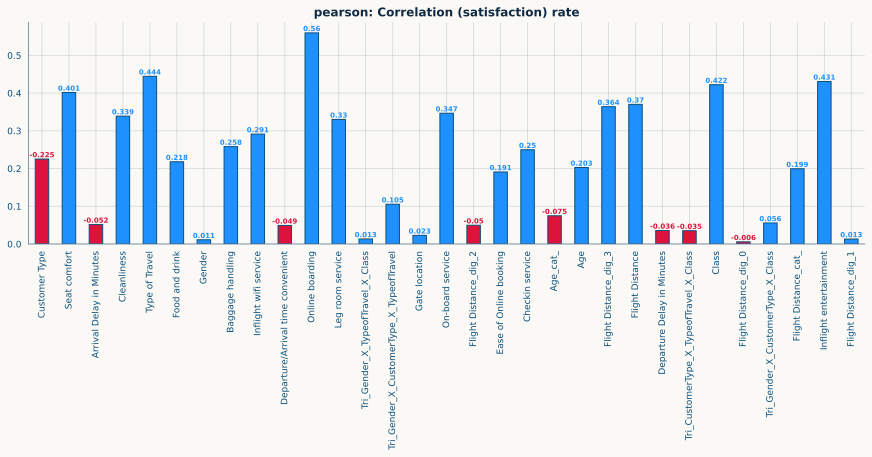

In [31]:
corr_type = ['pearson', 'spearman'][0]

plt.figure(figsize=(15, 4))
corr_df = train_X[FEATURES].corrwith(train_X[TARGET], method=corr_type)
corr_df.abs().plot(kind='bar', color=[CRIM if c < 0 else BLUE for c in corr_df.values])
for i, v in enumerate(corr_df.values):
    plt.text(
        i, np.abs(v) + 0.001, np.round(v, 3),
        size=7, weight='semibold', color=CRIM if v < 0 else BLUE,
        va='bottom', ha='center',
    )

plt.title(f"{corr_type}: Correlation ({TARGET}) rate")
plt.show()

In [32]:
# !rm -r /kaggle/working

In [33]:
# try:
#     import sdm
# except:
#     !pip install -q sdm
#     import sdm

# t = False

# x_1, x_2 = train_test_split(train[base_cols], train_size=100, stratify=train[TARGET], random_state=0)
# xs_1, xs_2 = train_test_split(test[base_cols], train_size=100, random_state=0)
# _X = train.copy() if t else x_1.reset_index(drop=True)

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# # A lossless, fully tensorized representation of the raw data on GPU:
# table = sdm.TableTensor.from_pandas(
#     df=_X,
#     stypes=sdm.infer_stypes(df, overrides={TARGET: "categorical"}),
#     device=device,
# )

# # Access to a variety of pre-trained structured data models:
# model = sdm.models.TabICLv2(device=device)

# # Default in-context learning forward pass:
# model(
#     # x_context=table[:300].drop_columns(TARGET),
#     # y_context=table[:300, "target"],
#     # x_query=table[300:].drop_columns("target"),
#     # num_estimators=8,

#     x_context=_X.drop_columns(TARGET),
#     y_context=_X[TARGET],
#     x_query=xs_1.drop_columns(TARGET),
#     num_estimators=2,
# )

# # Fit + Predict forward pass via key/value caching for fast inference:
# model.fit(
#     x=_X.drop_columns(TARGET),
#     y=_X[TARGET],
#     num_estimators=2,
# )
# preds = model.predict(xs_1)
# print(preds)
# # model.clear()

In [34]:
# try:
#     import sdm
# except:
#     !pip install -q sdm
#     import sdm

# # f = 3
# # skf = StratifiedKFold(n_splits=f, shuffle=True, random_state=42)
# t = False

# x_1, x_2 = train_test_split(train[base_cols], train_size=100, stratify=train[TARGET], random_state=0)
# xs_1, xs_2 = train_test_split(test[base_cols], train_size=100, random_state=0)
# _X = train.copy() if t else x_1.reset_index(drop=True)

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# # table = sdm.TableTensor.from_pandas(
# #     df=_X,
# #     stypes=sdm.infer_stypes(_X, overrides={TARGET: "categorical"}),
# #     device=device,
# # )

# # Access to a variety of pre-trained structured data models:
# model = sdm.models.TabICLv2(device=device)

# model = sdm.models.KumoTabular(task="classification", device=device)

# with torch.amp.autocast(
#     device.type,
#     dtype=torch.float16,
#     enabled=device.type == "cuda",
# ):
#     probs = model(
#         x_context=_X.drop_columns(TARGET),
#         y_context=_X[TARGET],
#         x_query=xs_1.drop_columns(TARGET),
#         num_estimators=2,
#     )

# print(probs)

In [35]:
CHECKPOINT = "checkpoints/"
shutil.rmtree(CHECKPOINT, ignore_errors=True)
os.makedirs(CHECKPOINT, exist_ok=True)

LR       = 0.001
EPOCHS   = 100
PATIENCE = 7

BATCH = 512 if torch.cuda.is_available() else 128
UNITS = [512, 256, 64]
DROP  = 0.4
ACT   = "gelu"

BUILD_MLP = True
scores = {}

MODEL = f"KERAS{ACT}({train_X.shape[1]}_{UNITS[0]}_{str(DROP).split('.')[1]})"

# for model_type in [True, False]:
#     MODEL_ = f"sciKeras{train_X.shape[1]}_mlp_" + str(model_type)
trainer = TrainerCV(
    model_mlp     = BUILD_MLP,
    model_name    = MODEL,
    train_df      = train_X,
    test_df       = test,
    features      = FEATURES,
    target        = TARGET,
    kfold         = skf,
    learning_rate = LR,
    layer_units   = UNITS,
    batch_size    = BATCH,
    epochs        = EPOCHS,
    patience      = PATIENCE,
    drop_rate     = DROP,
    activation    = ACT,
    eval_metric   = "auc",
    use_orig      = True,
    use_te        = True,
    # smooth        = 'auto',
)

result = trainer.fit()

#     scores[MODEL_] = result['avg_score']


===== Starting CV: KERASgelu(32_512_4) | =====


original_augmenting:   0%|          | 0/21 [00:00<?, ?it/s]

original_augmenting:   0%|          | 0/21 [00:00<?, ?it/s]

⚙️ Number of devices: 2

+++++ FOLD 1/5
⚡️ scikit_TE (smooth=auto) | features (2)
🟢 Training model graph *** Layers[Units] -> [512, 256, 64]
⧗ base_train: (559708, 52), base_valid: (139927, 52) +++



,Customer Type,Seat comfort,Arrival Delay in Minutes,Cleanliness,Type of Travel,Food and drink,Gender,Baggage handling,Inflight wifi service,Departure/Arrival time convenient,Online boarding,Leg room service,Tri_Gender_X_TypeofTravel_X_Class,Tri_Gender_X_CustomerType_X_TypeofTravel,Gate location,On-board service,Flight Distance_dig_2,Ease of Online booking,Checkin service,Age,Flight Distance_dig_3,Flight Distance,Departure Delay in Minutes,Tri_CustomerType_X_TypeofTravel_X_Class,Class,Flight Distance_dig_0,Tri_Gender_X_CustomerType_X_Class,Inflight entertainment,Flight Distance_dig_1,oTE_Age_mean,oTE_Flight Distance_mean,oTE_Inflight wifi service_mean,oTE_Departure/Arrival time convenient_mean,oTE_Ease of Online booking_mean,oTE_Gate location_mean,oTE_Food and drink_mean,oTE_Online boarding_mean,oTE_Seat comfort_mean,oTE_Inflight entertainment_mean,oTE_On-board service_mean,oTE_Leg room service_mean,oTE_Baggage handling_mean,oTE_Checkin service_mean,oTE_Cleanliness_mean,oTE_Departure Delay in Minutes_mean,oTE_Arrival Delay in Minutes_mean,oTE_Gender_mean,oTE_Customer Type_mean,oTE_Type of Travel_mean,oTE_Class_mean,TEauto_Flight Distance_cat_,TEauto_Age_cat_
0,0,1,0.0,1,0,1,0,4,4,4,4,4,0,0,3,3,6,4,3,36,0,694,0,0,0,4,0,1,9,0.354726,0.351852,0.600767,0.388614,0.531623,0.347062,0.199551,0.623011,0.223325,0.141946,0.318093,0.583096,0.480636,0.450794,0.196963,0.459390,0.473792,0.428975,0.478115,0.101326,0.187673,0.330480,0.304775
1,0,4,0.0,3,1,5,1,5,5,5,4,5,1,1,5,5,6,5,4,56,0,651,0,1,1,1,1,5,5,0.572727,0.331915,0.990178,0.424709,0.734676,0.568040,0.550882,0.623011,0.560293,0.650615,0.646379,0.614561,0.615916,0.460023,0.433075,0.459390,0.473792,0.440115,0.478115,0.583724,0.694434,0.304013,0.620894
3,0,3,0.0,3,0,3,1,3,3,5,3,5,2,2,3,4,6,3,4,10,1,1616,0,0,0,6,2,3,1,0.135036,0.443038,0.251825,0.424709,0.310104,0.347062,0.397424,0.137626,0.214078,0.273154,0.534584,0.614561,0.237979,0.460023,0.433075,0.459390,0.473792,0.440115,0.478115,0.101326,0.187673,0.543498,0.100171
4,1,5,0.0,5,1,5,0,5,3,4,3,4,3,3,4,5,4,3,3,23,0,481,5,2,0,1,3,5,8,0.391823,0.343750,0.251825,0.388614,0.310104,0.390698,0.550882,0.137626,0.651336,0.650615,0.646379,0.583096,0.615916,0.450794,0.612472,0.457397,0.473792,0.428975,0.239697,0.583724,0.187673,0.349636,0.350545
5,1,1,0.0,1,1,1,0,4,4,4,4,3,4,3,4,3,5,4,4,34,0,584,0,3,1,4,4,1,8,0.377161,0.314516,0.600767,0.388614,0.531623,0.390698,0.199551,0.623011,0.223325,0.141946,0.318093,0.276062,0.480636,0.460023,0.196963,0.459390,0.473792,0.428975,0.239697,0.583724,0.694434,0.313191,0.345387


⧗ proc_train: (559708, 54), proc_valid: (139927, 54) +++
⚡️ Keras MLP Build
Epoch 1/100
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - auc: 0.9492 - loss: 0.2666 - val_auc: 0.9563 - val_loss: 0.2380
Epoch 2/100
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - auc: 0.9537 - loss: 0.2452 - val_auc: 0.9576 - val_loss: 0.2331
Epoch 3/100
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - auc: 0.9548 - loss: 0.2401 - val_auc: 0.9581 - val_loss: 0.2309
Epoch 4/100
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - auc: 0.9552 - loss: 0.2377 - val_auc: 0.9585 - val_loss: 0.2296
Epoch 5/100
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - auc: 0.9556 - loss: 0.2363 - val_auc: 0.9587 - val_loss: 0.2290
Epoch 6/100
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - auc: 0.9558 - loss: 0.2352 - val_auc: 0.9590 - val_loss: 0.2285
Epoch 7/100
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - auc: 0.9562 - loss: 0.2342 - val_auc: 0.9591 - val_loss: 0.2279
Epoch 8/100
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - auc: 0.956

In [36]:
# --------------------------------------------------
# 5-FOLD CV: Keras(32)bd4_ | shape: (240000, 54)
# --------------------------------------------------
#  • Fold 1 AUC: 0.960474
#  • Fold 2 AUC: 0.959721
#  • Fold 3 AUC: 0.957175
#  • Fold 4 AUC: 0.959182
#  • Fold 5 AUC: 0.958908
# -------------------------------------------------|
# Overall score: 0.958215
# Average score: 0.959092 ± 0.001098
# -------------------------------------------------|
# 13.41 mins

In [37]:
print(f"oof_auc: {result['oof_score']}\navg_auc: {result['avg_score']}")

oof_auc: 0.959618
avg_auc: 0.959693


In [38]:
load_model = tf.keras.models.load_model(f"{CHECKPOINT}best_model.model.keras")
load_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ batch_normalization_20          │ (None, 54)             │           216 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 512)            │        28,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_23          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 535,093 (2.04 MB)

 Trainable params: 177,773 (694.43 KB)

 Non-trainable params: 1,772 (6.92 KB)

 Optimizer params: 355,548 (1.36 MB)

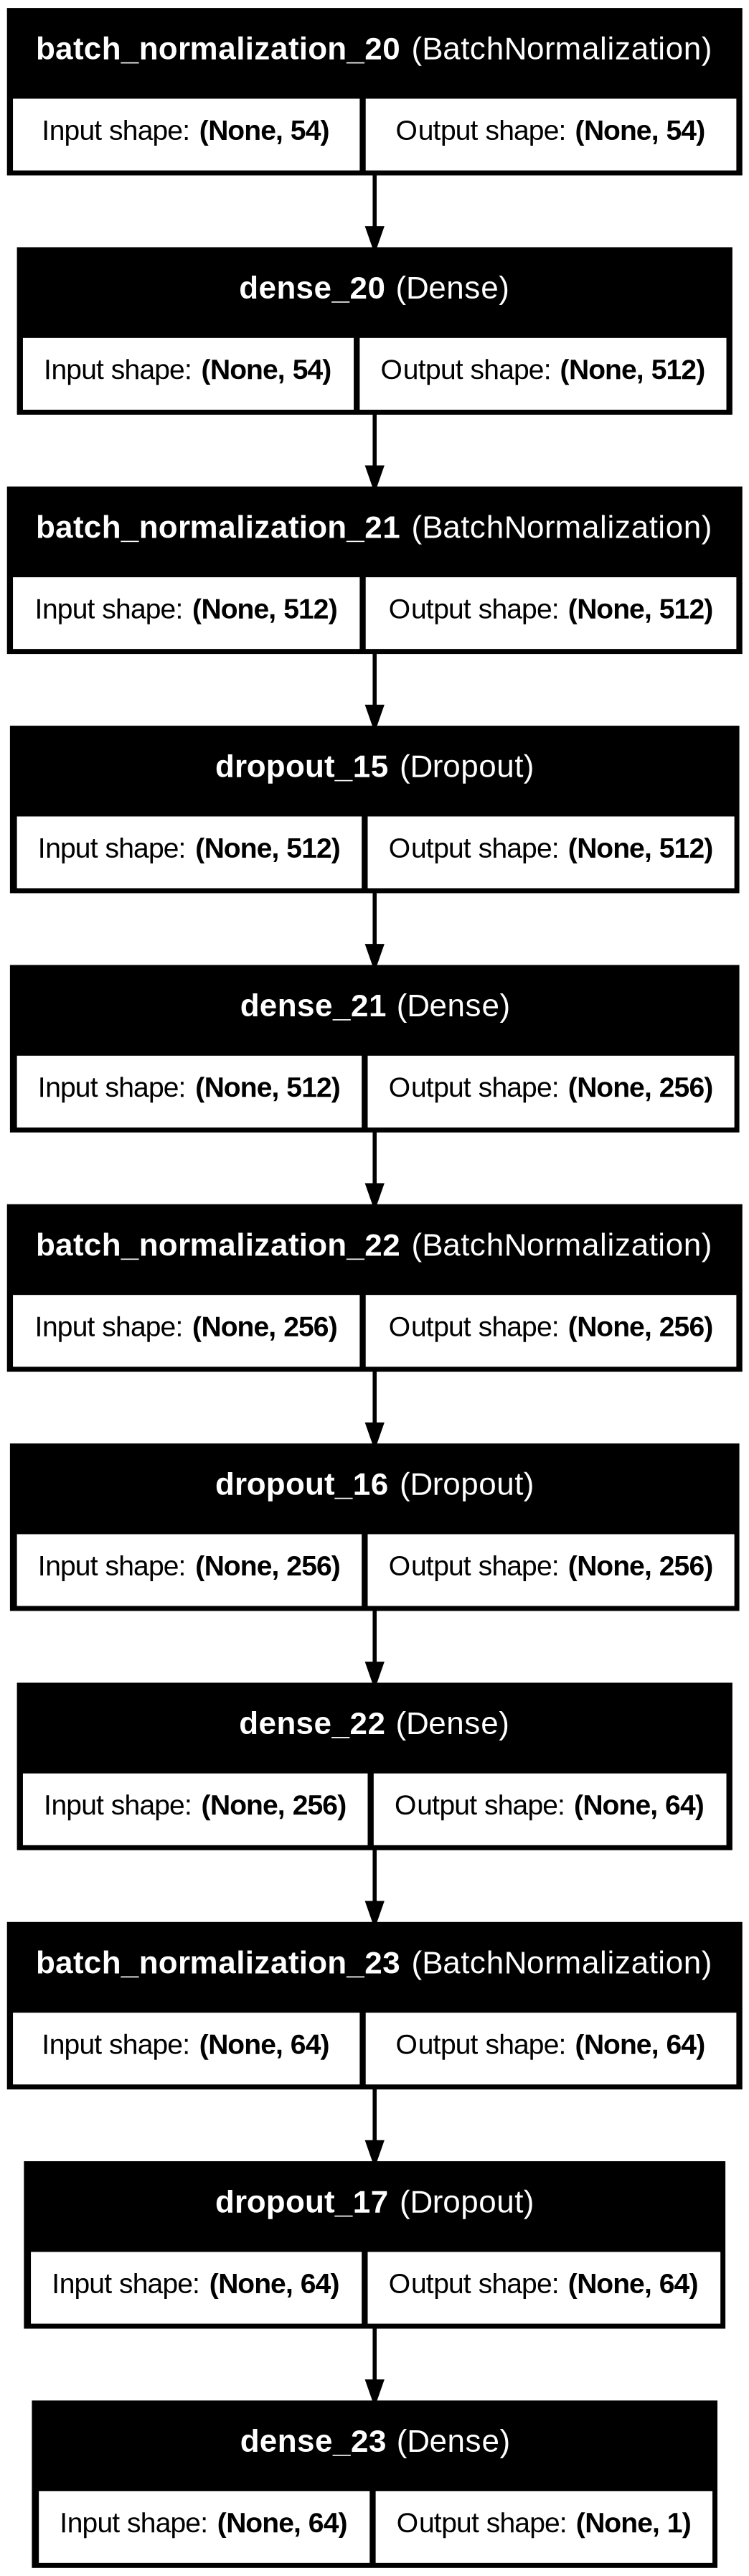

In [39]:
tf.keras.utils.plot_model(
    load_model,
    rankdir='TB',
    show_layer_names=True,
    show_shapes=True,
    expand_nested=True,
    # show_dtype=True,
)

# display(Image('/kaggle/working/model.png'))

In [40]:
def plot_results(history):
    for i in range(len(history)):
        loss_results = pd.DataFrame({'loss': history[i]['loss'], 'val_loss': history[i]['val_loss']})
        auc_results  = pd.DataFrame({'auc': history[i]['a_u_c'], 'val_auc': history[i]['val_auc']})

        plt.figure(figsize=(12, 4))

        marker, size, color = 'o', 8, 'darkorange'
    
        ## -- PLOT 1: LOSS --
        plt.subplot(121)
        sns.lineplot(loss_results, x=loss_results.index, y=loss_results['loss'], label='train', marker=marker)
        sns.lineplot(loss_results, x=loss_results.index, y=loss_results['val_loss'], label='valid', marker=marker)
        plt.title('LOSS', size=size, color=color)
        plt.xlabel('epochs')
        plt.ylabel('loss')
    
        ## -- PLOT 2: ACCURACY --
        plt.subplot(122)
        sns.lineplot(auc_results, x=auc_results.index, y=auc_results['auc'], label='train', marker=marker)
        sns.lineplot(auc_results, x=auc_results.index, y=auc_results['val_auc'], label='valid', marker=marker)
        plt.title('AUC', size=size, color=color)
        plt.xlabel('epochs')
        plt.ylabel('auc')

        stat_ = f"fold_score: {result['fold_score'][i]:.5f}"
        plt.scatter(x=auc_results.index[-1], y=max(auc_results['val_auc']), label=stat_, color='k')
    
        plt.suptitle(f"- FOLD {i+1} -", weight='semibold')
        plt.legend(loc='best')
        plt.tight_layout()
        plt.show()
        print()

print('Plot function ready')

Plot function ready


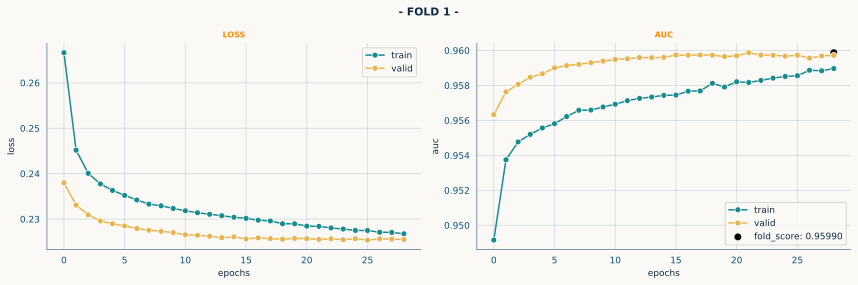

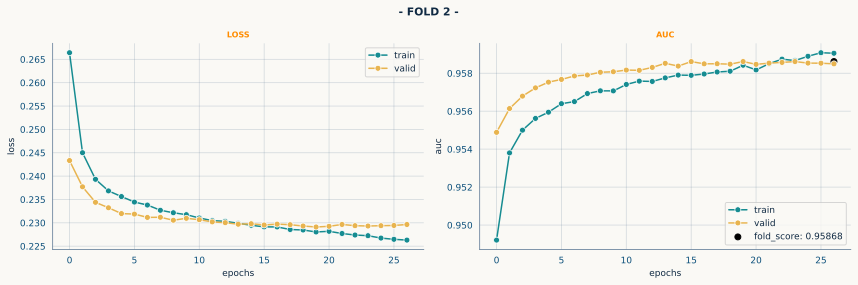

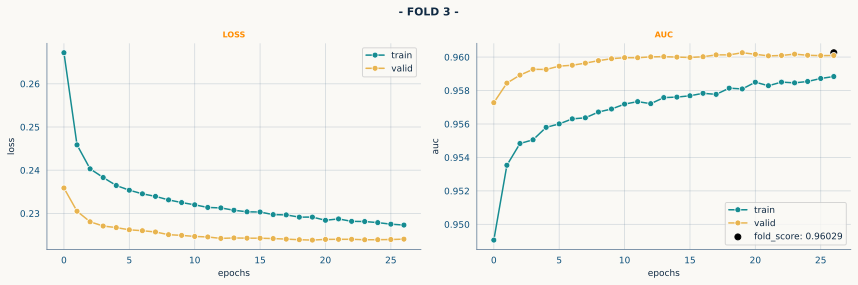

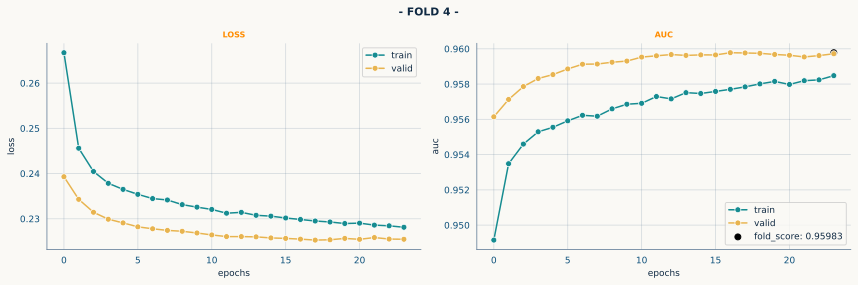

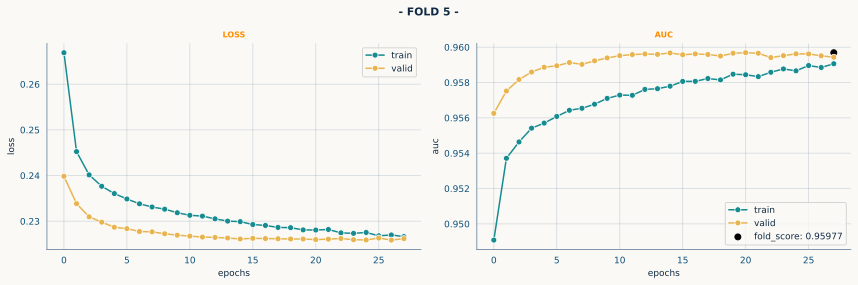

In [41]:
plot_results(result['history'])

💾 Saved file name KERASgelu(32_512_4)_959693



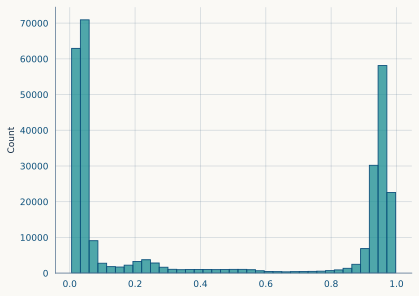

,id,satisfaction
0,699635,0.205312
1,699636,0.825235
2,699637,0.940107
3,699638,0.054106
4,699639,0.052910
...,...,...
299839,999474,0.030423
299840,999475,0.045586
299841,999476,0.201533
299842,999477,0.025068


In [42]:
n = f"{MODEL}_{str(result['avg_score']).split('.')[1]}"

submit[TARGET] = result["test_preds"].ravel()

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", result["oof_preds"])
np.save(f"test_{n}.npy", result["test_preds"])

print(f"💾 Saved file name {n}\n")

sns.histplot(submit[TARGET].values)
plt.show()

submit

In [43]:
# ## -- PLOTTING RESULTS --
# histories = result['history']

# for i, data in tqdm(enumerate(histories), total=len(histories)):
#     loss_results = pd.DataFrame({'train_loss': data['loss'], 'val_loss': data['val_loss']})
#     auc_results = pd.DataFrame({'train_auc': data['auc'], 'val_auc': data['val_auc']})
#     plt.figure(figsize=(16, 5))
#     marker = 'o'

#     ## -- PLOT LOSS --
#     plt.subplot(121)
#     sns.lineplot(loss_results, x=loss_results.index, y=loss_results.train_loss, label='train_loss', marker=marker)
#     sns.lineplot(loss_results, x=loss_results.index, y=loss_results.val_loss, label='val_loss', marker=marker)
#     plt.title('LOSS', fontweight='semibold')
#     plt.xlabel('Epochs')
#     plt.ylabel('Loss')

#     ## -- PLOT AUC --
#     plt.subplot(122)
#     sns.lineplot(auc_results, x=auc_results.index, y=auc_results.train_auc, label='train_auc', marker=marker)
#     sns.lineplot(auc_results, x=auc_results.index, y=auc_results.val_auc, label='val_auc', marker=marker)
#     plt.title('ROC-AUC', fontweight='semibold')
#     plt.xlabel('Epochs')
#     plt.ylabel('AUC')

#     stat_ = f"fold_auc: {result['fold_score'][i]:.5f}"
#     plt.scatter(x=0, y=0, label=stat_, color='y')

#     plt.suptitle(f"FOLD {i+1}", fontsize=16, fontweight='semibold')
#     plt.legend(loc='best')
#     plt.tight_layout()
#     plt.show()
#     print()

In [44]:
# !rm -r /kaggle/working